In [ ]:
%pip install koreanize-matplotlib

In [7]:
# 1. 수집
# 2. 탐색
# 2-1) 데이터를 읽고, 구조(스키마)확인, 자료형

In [8]:
import koreanize_matplotlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:
# pandas, seaborn 라이브러리 사용 옵션 설정
pd.set_option("display.max_columns", 100) #  최대 100개 열까지 표시한다.
pd.set_option("display.max_rows", 100) # 최대 100개 행까지 표시한다.
pd.set_option("display.width", 140) # 표의 출력 너비를 140자로 설정해 줄바꿈을 줄인다.
# seaborn 그래프의 기본 모양을 흰 배경과 격자선으로 설정하고, 노트북에 맞는 글자·요소 크기를 사용한다.
sns.set_theme(style="whitegrid", context="notebook")

In [10]:
df = pd.read_csv('train.csv')
# df.head(5)
df.head(5).T

,0,1,2,3,4
Id,1,2,3,4,5
MSSubClass,60,20,60,70,60
MSZoning,RL,RL,RL,RL,RL
LotFrontage,65.0,80.0,68.0,60.0,84.0
LotArea,8450,9600,11250,9550,14260
Street,Pave,Pave,Pave,Pave,Pave
Alley,NaN,NaN,NaN,NaN,NaN
LotShape,Reg,Reg,IR1,IR1,IR1
LandContour,Lvl,Lvl,Lvl,Lvl,Lvl
Utilities,AllPub,AllPub,AllPub,AllPub,AllPub


In [11]:
df.shape

(1460, 81)

In [12]:
# duplicated() 행->이전에 동일한 행이 존재하면 True 아니면 Fasle -> sum()집계하면 True 개수
df.duplicated().sum()

np.int64(0)

In [13]:
# 컬럼의 이름만 중복확인
df.columns.duplicated().sum()

np.int64(0)

In [14]:
# 자료형
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

In [15]:
# df[조건][열이름]
# df.loc[조건, [열이름]]
df[['PoolQC', 'PoolArea']]

display(df.loc[df['PoolQC'].isna(), ['PoolQC', 'PoolArea']]) # df[df['PoolQC'].isna()]['PoolQC', 'PoolArea']
display(df.loc[df['PoolQC'].notna(), ['PoolQC', 'PoolArea']])

,PoolQC,PoolArea
0,NaN,0
1,NaN,0
2,NaN,0
3,NaN,0
4,NaN,0
...,...,...
1455,NaN,0
1456,NaN,0
1457,NaN,0
1458,NaN,0


,PoolQC,PoolArea
197,Ex,512
810,Fa,648
1170,Gd,576
1182,Ex,555
1298,Gd,480
1386,Fa,519
1423,Gd,738


In [16]:
df.dtypes.value_counts()

str        43
int64      35
float64     3
Name: count, dtype: int64

In [17]:
# 변수 탐색 + 품질 검사(논리 검증)

In [18]:
# 고유값
# df[컬럼].nunique() 값
df['PoolQC'].nunique(dropna=False)

# t1 = [df[c].nunique(dropna=False) for c in df.columns]

# 같은 표현
t1 = []
for c in df.columns: # for문을 많이 사용해야....
  t1.append(df[c].nunique(dropna=False))
t1

[1460,
 15,
 5,
 111,
 1073,
 2,
 3,
 4,
 4,
 2,
 5,
 3,
 25,
 9,
 8,
 5,
 8,
 10,
 9,
 112,
 61,
 6,
 8,
 15,
 16,
 4,
 328,
 4,
 5,
 6,
 5,
 5,
 5,
 7,
 637,
 7,
 144,
 780,
 721,
 6,
 5,
 2,
 6,
 753,
 417,
 24,
 861,
 4,
 3,
 4,
 3,
 8,
 4,
 4,
 12,
 7,
 4,
 6,
 7,
 98,
 4,
 5,
 441,
 6,
 6,
 3,
 274,
 202,
 120,
 20,
 76,
 8,
 4,
 5,
 5,
 21,
 12,
 5,
 9,
 6,
 663]

In [19]:
df.dtypes.values

array([dtype('int64'), dtype('int64'),
       <StringDtype(storage='python', na_value=nan)>, dtype('float64'),
       dtype('int64'), <StringDtype(storage='python', na_value=nan)>,
       <StringDtype(storage='python', na_value=nan)>,
       <StringDtype(storage='python', na_value=nan)>,
       <StringDtype(storage='python', na_value=nan)>,
       <StringDtype(storage='python', na_value=nan)>,
       <StringDtype(storage='python', na_value=nan)>,
       <StringDtype(storage='python', na_value=nan)>,
       <StringDtype(storage='python', na_value=nan)>,
       <StringDtype(storage='python', na_value=nan)>,
       <StringDtype(storage='python', na_value=nan)>,
       <StringDtype(storage='python', na_value=nan)>,
       <StringDtype(storage='python', na_value=nan)>, dtype('int64'),
       dtype('int64'), dtype('int64'), dtype('int64'),
       <StringDtype(storage='python', na_value=nan)>,
       <StringDtype(storage='python', na_value=nan)>,
       <StringDtype(storage='python', na_value

In [20]:
# 고유값 품질 요약
unque_summary = pd.DataFrame({
    'column': df.columns,
    'dtype': df.dtypes.values,
    'nunique(na)': [df[c].nunique(dropna=False) for c in df.columns], # t1
    'nunique(ratio)': [df[c].nunique(dropna=False)/len(df) for c in df.columns],
})
unque_summary

,column,dtype,nunique(na),nunique(ratio)
0,Id,int64,1460,1.000000
1,MSSubClass,int64,15,0.010274
2,MSZoning,str,5,0.003425
3,LotFrontage,float64,111,0.076027
4,LotArea,int64,1073,0.734932
5,Street,str,2,0.001370
6,Alley,str,3,0.002055
7,LotShape,str,4,0.002740
8,LandContour,str,4,0.002740
9,Utilities,str,2,0.001370


In [21]:
# 개별 변수의 고유값 상세히 탐색 value_counts()

df['Id'].value_counts(dropna=False)

Id
1       1
2       1
3       1
4       1
5       1
       ..
1456    1
1457    1
1458    1
1459    1
1460    1
Name: count, Length: 1460, dtype: int64

In [77]:
for nc in df.select_dtypes('number').columns:
  display(df[nc].value_counts(dropna=False).head(3))

Id
1    1
2    1
3    1
Name: count, dtype: int64

MSSubClass
20    536
60    299
50    144
Name: count, dtype: int64

LotFrontage
NaN     259
60.0    143
70.0     70
Name: count, dtype: int64

LotArea
7200    25
9600    24
6000    17
Name: count, dtype: int64

OverallQual
5    397
6    374
7    319
Name: count, dtype: int64

OverallCond
5    821
6    252
7    205
Name: count, dtype: int64

... (28 outputs left out)

MiscVal
0      1408
400      11
500       8
Name: count, dtype: int64

MoSold
6    253
7    234
5    204
Name: count, dtype: int64

YrSold
2009    338
2007    329
2006    314
Name: count, dtype: int64

SalePrice
140000    20
135000    17
145000    14
Name: count, dtype: int64

In [78]:
for oc in df.select_dtypes('object').columns:
  display(df[oc].value_counts(dropna=False).head(3))

C:\Users\user\AppData\Local\Temp\ipykernel_21912\3416072954.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for oc in df.select_dtypes('object').columns:


MSZoning
RL    1151
RM     218
FV      65
Name: count, dtype: int64

Street
Pave    1454
Grvl       6
Name: count, dtype: int64

Alley
NaN     1369
Grvl      50
Pave      41
Name: count, dtype: int64

LotShape
Reg    925
IR1    484
IR2     41
Name: count, dtype: int64

LandContour
Lvl    1311
Bnk      63
HLS      50
Name: count, dtype: int64

... (34 outputs left out)

Fence
NaN      1179
MnPrv     157
GdPrv      59
Name: count, dtype: int64

MiscFeature
NaN     1406
Shed      49
Gar2       2
Name: count, dtype: int64

SaleType
WD     1267
New     122
COD      43
Name: count, dtype: int64

SaleCondition
Normal     1198
Partial     125
Abnorml     101
Name: count, dtype: int64

In [24]:
for oc in df.select_dtypes('object').columns:
  print(len(df[oc].value_counts(dropna=False)))

5
2
3
4
4
2
5
3
25
9
8
5
8
6
8
15
16
4
4
5
6
5
5
5
7
7
6
5
2
6
4
7
6
7
4
6
6
3
4
5
5
9
6


C:\Users\user\AppData\Local\Temp\ipykernel_21912\1539859841.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for oc in df.select_dtypes('object').columns:


In [25]:
# 결측치 품질 요약
# 탐색, 확인이 목적 -> 대체/다른값으로 기록, ....

na_summary = pd.DataFrame({
    'column': df.columns,
    'dtype': df.dtypes.values,
    'na(count)': df.isna().sum(),
}).sort_values('na(count)', ascending=False)

na_summary

,column,dtype,na(count)
PoolQC,PoolQC,str,1453
MiscFeature,MiscFeature,str,1406
Alley,Alley,str,1369
Fence,Fence,str,1179
MasVnrType,MasVnrType,str,872
FireplaceQu,FireplaceQu,str,690
LotFrontage,LotFrontage,float64,259
GarageQual,GarageQual,str,81
GarageFinish,GarageFinish,str,81
GarageType,GarageType,str,81


In [26]:
# 변수값 논리검정

In [27]:
# 수치형 기술 통계량 점검
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0


In [28]:
df.describe(include='object').T

C:\Users\user\AppData\Local\Temp\ipykernel_21912\1760094569.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object').T


,count,unique,top,freq
MSZoning,1460,5,RL,1151
Street,1460,2,Pave,1454
Alley,91,2,Grvl,50
LotShape,1460,4,Reg,925
LandContour,1460,4,Lvl,1311
Utilities,1460,2,AllPub,1459
LotConfig,1460,5,Inside,1052
LandSlope,1460,3,Gtl,1382
Neighborhood,1460,25,NAmes,225
Condition1,1460,9,Norm,1260


<Axes: >

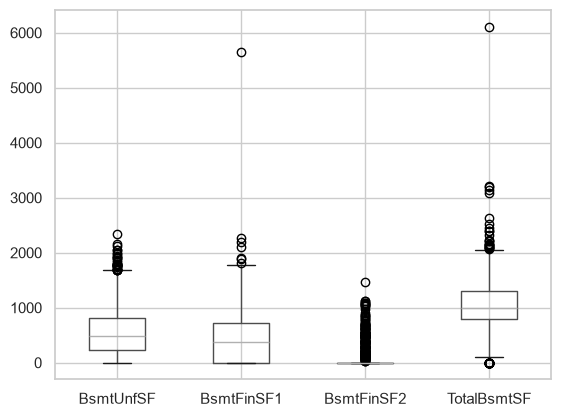

In [29]:
df.boxplot(['BsmtUnfSF','BsmtFinSF1','BsmtFinSF2', 'TotalBsmtSF'])

In [30]:
df[df['BsmtFinSF1'] == 5644]

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
1298,1299,60,RL,313.0,63887,Pave,NaN,IR3,Bnk,AllPub,Corner,Gtl,Edwards,Feedr,Norm,1Fam,2Story,10,5,2008,2008,Hip,ClyTile,Stucco,Stucco,Stone,796.0,Ex,TA,PConc,Ex,TA,Gd,GLQ,5644,Unf,0,466,6110,GasA,Ex,Y,SBrkr,4692,950,0,5642,2,0,2,1,3,1,Ex,12,Typ,3,Gd,Attchd,2008.0,Fin,2,1418,TA,TA,Y,214,292,0,0,0,480,Gd,NaN,NaN,0,1,2008,New,Partial,160000


In [31]:
# 예시1) 가격·면적의 음수 여부: SalePrice, LotArea, GrLivArea가 0보다 작은 행을 찾는다.
# 예시2) 연도 관계: YearBuilt가 YrSold보다 큰 집을 찾는다. 리모델링 연도(YearRemodAdd)가 판매 연도보다 늦은지도 확인한다.
# 예시3) 면적 합계: GrLivArea가 1stFlrSF + 2ndFlrSF + LowQualFinSF와 맞는지 확인한다.
# 예시4) 방·욕실 수: BedroomAbvGr, FullBath, GarageCars 등에 음수나 비현실적인 값이 있는지 확인한다.
# 예시5) 월 범위: MoSold가 1~12 범위인지 확인한다.
# 예시6) 식별자 중복: Id가 중복되거나 비어 있는지 확인한다.

In [32]:
# 예시6) 식별자 중복: Id가 중복되거나 비어 있는지 확인한다.
# 전체1460개 고유값 1460 -> 식별자 검증

# RDB의 PK 검증
# 결측치 확인
print(df['Id'].isna().sum()) # 0 -> 식별자 결측치가 없다.
# 중복값 확인
print(df['Id'].duplicated().sum())

# 만약 위에서 하나라도 1이 있다면 조건식으로 행을 탐색
df[(df['Id'].isna() == True) | (df['Id'].duplicated() == True)]

0
0


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice


In [33]:
# 예시5) 월 범위: MoSold가 1~12 범위인지 확인한다.
df['MoSold'].unique() # 1 ~ 12 , 0,

array([ 2,  5,  9, 12, 10,  8, 11,  4,  1,  7,  3,  6])

In [34]:
df[(df['MoSold']<1) | (df['MoSold']>12)]

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice


In [35]:
# 예시4) 방·욕실 수: BedroomAbvGr, FullBath, GarageCars 등에 음수나 비현실적인 값이 있는지 확인한다.

df[(df['BedroomAbvGr']<0) | (df['FullBath']<0) | (df['GarageCars']<0)]

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice


In [36]:
# 예시3) 면적 합계: GrLivArea가 1stFlrSF + 2ndFlrSF + LowQualFinSF와 맞는지 확인한다.
# df[['GrLivArea','1stFlrSF','2ndFlrSF','LowQualFinSF']].isna().sum()
# df[['GrLivArea','1stFlrSF','2ndFlrSF','LowQualFinSF']]

df[df['GrLivArea'] != (df['1stFlrSF']+df['2ndFlrSF']+df['LowQualFinSF'])]

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice


# ~ 11/2

EDA 탐색 결과 보고서.md

1. 데이터셋 개요, 구조
2. 변수 - 변수 데이터 사전 참조
8. 데이터품질확인(논리검증)



---


3. 결측치
4. 이상치
5. 변수 분포(수치-히스토그램,박스플롯 / 범주-막대)
6. 타겟 분포, 분석
7. 상관관계

---

9. 전처리대한 의견
10. 아이디어 - 특성공학(요약변수, 파생변수)
11. 팀 결정사항

---

12. 탐색 문서를 바탕으로 1/n, 함께 전치리 ex) 결측치 처리

# 11/3 ~

In [37]:
numeric_cols = df.select_dtypes('number').columns
category_cols = df.select_dtypes('object').columns

print(numeric_cols)
print(category_cols)

Index(['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1',
       'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath',
       'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea',
       'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold', 'SalePrice'],
      dtype='str')
Index(['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1',
       'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual',
       'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC',
       'CentralAir', 'Electrical', 'Kitc

C:\Users\user\AppData\Local\Temp\ipykernel_21912\1833262733.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  category_cols = df.select_dtypes('object').columns


In [38]:
# 히스토그램
# 분포, 값 집중,.... -> 탐색 내용정리 -> 조치 -> 로그변환 후 전/후 평가지표 확인, 제거, .....

df[numeric_cols].hist(figsize=(15, 12))

array([[<Axes: title={'center': 'Id'}>,
        <Axes: title={'center': 'MSSubClass'}>,
        <Axes: title={'center': 'LotFrontage'}>,
        <Axes: title={'center': 'LotArea'}>,
        <Axes: title={'center': 'OverallQual'}>,
        <Axes: title={'center': 'OverallCond'}>],
       [<Axes: title={'center': 'YearBuilt'}>,
        <Axes: title={'center': 'YearRemodAdd'}>,
        <Axes: title={'center': 'MasVnrArea'}>,
        <Axes: title={'center': 'BsmtFinSF1'}>,
        <Axes: title={'center': 'BsmtFinSF2'}>,
        <Axes: title={'center': 'BsmtUnfSF'}>],
       [<Axes: title={'center': 'TotalBsmtSF'}>,
        <Axes: title={'center': '1stFlrSF'}>,
        <Axes: title={'center': '2ndFlrSF'}>,
        <Axes: title={'center': 'LowQualFinSF'}>,
        <Axes: title={'center': 'GrLivArea'}>,
        <Axes: title={'center': 'BsmtFullBath'}>],
       [<Axes: title={'center': 'BsmtHalfBath'}>,
        <Axes: title={'center': 'FullBath'}>,
        <Axes: title={'center': 'HalfBath'}>,

In [39]:
# y 탐색
df['SalePrice'].hist()

<Axes: >

In [40]:
np.log1p(df['SalePrice']).hist()

<Axes: >

In [41]:
# 이상치 - 박스플롯
print(len(numeric_cols))
df[numeric_cols].plot(kind='box', subplots=True, layout=(8, 5), figsize=(20, 15))

38


Id                  Axes(0.125,0.798085;0.133621x0.0819149)
MSSubClass       Axes(0.285345,0.798085;0.133621x0.0819149)
LotFrontage       Axes(0.44569,0.798085;0.133621x0.0819149)
LotArea          Axes(0.606034,0.798085;0.133621x0.0819149)
OverallQual      Axes(0.766379,0.798085;0.133621x0.0819149)
OverallCond         Axes(0.125,0.699787;0.133621x0.0819149)
YearBuilt        Axes(0.285345,0.699787;0.133621x0.0819149)
YearRemodAdd      Axes(0.44569,0.699787;0.133621x0.0819149)
MasVnrArea       Axes(0.606034,0.699787;0.133621x0.0819149)
BsmtFinSF1       Axes(0.766379,0.699787;0.133621x0.0819149)
BsmtFinSF2          Axes(0.125,0.601489;0.133621x0.0819149)
BsmtUnfSF        Axes(0.285345,0.601489;0.133621x0.0819149)
TotalBsmtSF       Axes(0.44569,0.601489;0.133621x0.0819149)
1stFlrSF         Axes(0.606034,0.601489;0.133621x0.0819149)
2ndFlrSF         Axes(0.766379,0.601489;0.133621x0.0819149)
LowQualFinSF        Axes(0.125,0.503191;0.133621x0.0819149)
GrLivArea        Axes(0.285345,0.503191;

In [42]:
# 상관관계 x1값이 움지이면, x?값이 같이 움직이다. -> 변수간에 상관관계가 높으면 다중공선성 문제, X,y간 상관관계가 높다 중요

In [43]:
cor = df.corr(numeric_only=True, method='pearson') # pearson기본값(연속형 수치) method='spearman'(순서가 있는 범주형 수치)

cor['SalePrice']

Id              -0.021917
MSSubClass      -0.084284
LotFrontage      0.351799
LotArea          0.263843
OverallQual      0.790982
OverallCond     -0.077856
YearBuilt        0.522897
YearRemodAdd     0.507101
MasVnrArea       0.477493
BsmtFinSF1       0.386420
BsmtFinSF2      -0.011378
BsmtUnfSF        0.214479
TotalBsmtSF      0.613581
1stFlrSF         0.605852
2ndFlrSF         0.319334
LowQualFinSF    -0.025606
GrLivArea        0.708624
BsmtFullBath     0.227122
BsmtHalfBath    -0.016844
FullBath         0.560664
HalfBath         0.284108
BedroomAbvGr     0.168213
KitchenAbvGr    -0.135907
TotRmsAbvGrd     0.533723
Fireplaces       0.466929
GarageYrBlt      0.486362
GarageCars       0.640409
GarageArea       0.623431
WoodDeckSF       0.324413
OpenPorchSF      0.315856
EnclosedPorch   -0.128578
3SsnPorch        0.044584
ScreenPorch      0.111447
PoolArea         0.092404
MiscVal         -0.021190
MoSold           0.046432
YrSold          -0.028923
SalePrice        1.000000
Name: SalePr

In [44]:
plt.figure(figsize=(30, 25))
sns.heatmap(cor, annot=True, fmt='.2f')

<Axes: >

In [45]:
# 결측치
missing = df.isna().sum().sort_values(ascending=False)

missing[missing > 0]

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageQual        81
GarageFinish      81
GarageType        81
GarageYrBlt       81
GarageCond        81
BsmtFinType2      38
BsmtExposure      38
BsmtCond          37
BsmtQual          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64

None으로 처리하는 범주형 변수와 train 결측 수:

Alley: 1,369건. 골목 접근로가 없는 경우로 해석한다.

BsmtQual: 37건. 지하실이 없는 경우로 해석한다.TotalBsmtSF(지하실 면적) 0

BsmtCond: 37건. 지하실이 없는 경우로 해석한다.TotalBsmtSF가(지하실 면적) 0

BsmtExposure: 38건. 지하실이 없는 경우로 해석한다.TotalBsmtSF(지하실 면적) 0

BsmtFinType1: 37건. 지하실이 없는 경우로 해석한다.TotalBsmtSF(지하실 면적) 0

BsmtFinType2: 38건. 지하실이 없는 경우로 해석한다.TotalBsmtSF(지하실 면적) 0

FireplaceQu: 690건. 벽난로가 없는 경우로 해석한다.Fireplaces(벽난로 개수)0

GarageType: 81건. 차고가 없는 경우로 해석한다.GarageArea(차고 면적) 0

GarageFinish: 81건. 차고가 없는 경우로 해석한다.GarageArea(차고 면적) 0

GarageQual: 81건. 차고가 없는 경우로 해석한다.GarageArea(차고 면적) 0

GarageCond: 81건. 차고가 없는 경우로 해석한다.GarageArea(차고 면적) 0

PoolQC: 1,453건. 수영장이 없는 경우로 해석한다.PoolArea(수영장 면적) 0

Fence: 1,179건. 울타리가 없는 경우로 해석한다.

MiscFeature: 1,406건. 기타 시설이 없는 경우로 해석한다.

MasVnrType은 MasVnrArea와 같이 판단한다.

MasVnrType이 결측이고 MasVnrArea가 0이면 장식용 석재가 없는 것으로 보고
None으로 바꾼다.

MasVnrArea가 0이 아닌데 MasVnrType이 결측이면 임의로 종류를 추정하지 않고 Unknown으로 표시한다.

GarageYrBlt은 GarageType이 None인 행에서 결측이면 0으로 처리한다. 이는 차고가 없는 집에 차고 건축연도가 없다는 상태를 표현한다.

In [46]:
# 전처리 의견에 대한 검정

print(len(df[df['BsmtQual'].isna() & (df['TotalBsmtSF'] == 0)]))
df[df['BsmtQual'].isna() & (df['TotalBsmtSF'] != 0)][['BsmtQual','TotalBsmtSF']]

37


,BsmtQual,TotalBsmtSF


In [47]:
print(len(df[df['BsmtCond'].isna() & (df['TotalBsmtSF'] == 0)]))
df[df['BsmtCond'].isna() & (df['TotalBsmtSF'] != 0)][['BsmtCond','TotalBsmtSF']]

37


,BsmtCond,TotalBsmtSF


In [48]:
print(len(df[df['BsmtFinType2'].isna() & (df['TotalBsmtSF'] == 0)]))
df[df['BsmtFinType2'].isna() & (df['TotalBsmtSF'] != 0)][['BsmtFinType2','TotalBsmtSF']]

37


,BsmtFinType2,TotalBsmtSF
332,NaN,3206


In [49]:
print(len(df[df['FireplaceQu'].isna() & (df['Fireplaces'] == 0)]))
df[df['FireplaceQu'].isna() & (df['Fireplaces'] != 0)][['FireplaceQu','TotalBsmtSF']]

690


,FireplaceQu,TotalBsmtSF


In [50]:
print(len(df[df['PoolQC'].isna() & (df['PoolArea'] == 0)]))
df[df['PoolQC'].isna() & (df['PoolArea'] != 0)][['PoolQC','PoolArea']]

1453


,PoolQC,PoolArea


In [51]:
print(len(df[df['MasVnrType'].isna() & (df['MasVnrArea'] == 0)]))
df[df['MasVnrType'].isna() & (df['MasVnrArea'] != 0)][['MasVnrType','MasVnrArea']]

859


,MasVnrType,MasVnrArea
234,NaN,NaN
529,NaN,NaN
624,NaN,288.0
650,NaN,NaN
773,NaN,1.0
936,NaN,NaN
973,NaN,NaN
977,NaN,NaN
1230,NaN,1.0
1243,NaN,NaN


# 전처리 ~

In [52]:
# 전치리전에 분할 먼저 진행
# 분할 -> 홀드아웃, 교차검증

# 변수 : Id(식별자), SalePrice(y)

X = df.drop(columns=['Id', 'SalePrice'])
y = df['SalePrice']

print(X.shape)
print(y.shape)

(1460, 79)
(1460,)


In [53]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, root_mean_squared_error

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=1)

print(X_train.shape)
print(X_val.shape)
print(y_train.shape)
print(y_val.shape)

(1168, 79)
(292, 79)
(1168,)
(292,)


In [54]:
# 결측치 처리 1) "None", "Unknown"
# 전체 결측치 수는
print('전:',X_train.isna().sum().sum())
print('전:',X_val.isna().sum().sum())

# 결측치를 "None"값으로 대처하는 컬럼들
na_cols =[
    'Alley','BsmtCond','BsmtCond','BsmtFinType1','FireplaceQu','GarageType','GarageFinish','GarageQual','GarageCond','PoolQC','Fence','MiscFeature'
]

for nc in na_cols:
  X_train[nc] = X_train[nc].fillna('None')
  X_val[nc] = X_val[nc].fillna('None')



전: 6247
전: 1582


In [55]:
print('후:',X_train.isna().sum().sum())
print('후:',X_val.isna().sum().sum())

후: 1057
후: 277


In [56]:
t1 = X_train.isna().sum()
display(t1[t1>0])

t2 = X_val.isna().sum()
display(t2[t2>0])

LotFrontage     209
MasVnrType      686
MasVnrArea        8
BsmtQual         30
BsmtExposure     31
BsmtFinType2     31
Electrical        1
GarageYrBlt      61
dtype: int64

LotFrontage      50
MasVnrType      186
BsmtQual          7
BsmtExposure      7
BsmtFinType2      7
GarageYrBlt      20
dtype: int64

In [57]:
X_train.loc[X_train['BsmtExposure'].isna(), ['BsmtExposure', 'TotalBsmtSF']]

,BsmtExposure,TotalBsmtSF
520,NaN,0
90,NaN,0
1048,NaN,0
392,NaN,0
156,NaN,0
553,NaN,0
868,NaN,0
17,NaN,0
705,NaN,0
1035,NaN,0


In [58]:
# BsmtExposure, BsmtFinType2는 BsmtExposure결측치이고, TotalBsmtSF값이 0이면 "None", 아니면 "Unknown"
cond = X_train['BsmtExposure'].isna() & (X_train['TotalBsmtSF']==0)
X_train.loc[cond, 'BsmtExposure'] = "None"
X_train.loc[X_train['BsmtExposure'].isna(), 'BsmtExposure'] = "Unknown"


In [59]:
display(X_train['BsmtExposure'].value_counts())

BsmtExposure
No         745
Av         186
Gd         110
Mn          96
None        30
Unknown      1
Name: count, dtype: int64

In [60]:
cond = X_val['BsmtExposure'].isna() & (X_val['TotalBsmtSF']==0)
X_val.loc[cond, 'BsmtExposure'] = "None"

X_val.loc[X_val['BsmtExposure'].isna(), 'BsmtExposure'] = "Unknown"

In [61]:

display(X_val['BsmtExposure'].value_counts())

BsmtExposure
No      208
Av       35
Gd       24
Mn       18
None      7
Name: count, dtype: int64

In [62]:
t1 = X_train.isna().sum()
display(t1[t1>0])

t2 = X_val.isna().sum()
display(t2[t2>0])

LotFrontage     209
MasVnrType      686
MasVnrArea        8
BsmtQual         30
BsmtFinType2     31
Electrical        1
GarageYrBlt      61
dtype: int64

LotFrontage      50
MasVnrType      186
BsmtQual          7
BsmtFinType2      7
GarageYrBlt      20
dtype: int64

In [63]:
cond = X_train['BsmtFinType2'].isna() & (X_train['TotalBsmtSF']==0)
X_train.loc[cond, 'BsmtFinType2'] = "None"
X_train.loc[X_train['BsmtFinType2'].isna(), 'BsmtFinType2'] = "Unknown"

cond = X_val['BsmtFinType2'].isna() & (X_val['TotalBsmtSF']==0)
X_val.loc[cond, 'BsmtFinType2'] = "None"

X_val.loc[X_val['BsmtFinType2'].isna(), 'BsmtFinType2'] = "Unknown"

In [64]:
t1 = X_train.isna().sum()
display(t1[t1>0])

t2 = X_val.isna().sum()
display(t2[t2>0])

LotFrontage    209
MasVnrType     686
MasVnrArea       8
BsmtQual        30
Electrical       1
GarageYrBlt     61
dtype: int64

LotFrontage     50
MasVnrType     186
BsmtQual         7
GarageYrBlt     20
dtype: int64

In [65]:
X_train['BsmtFinType2'].value_counts()

BsmtFinType2
Unf        1014
Rec          45
None         30
LwQ          30
BLQ          21
ALQ          16
GLQ          11
Unknown       1
Name: count, dtype: int64

In [66]:
t1 = X_train.isna().sum()
display(t1[t1>0])

LotFrontage    209
MasVnrType     686
MasVnrArea       8
BsmtQual        30
Electrical       1
GarageYrBlt     61
dtype: int64

In [67]:
cond = X_train['MasVnrType'].isna() & (X_train['MasVnrArea']==0)
X_train.loc[cond, 'MasVnrType'] = 'None'
X_train['MasVnrType'] = X_train['MasVnrType'].fillna('Unknown')

In [68]:
cond = X_val['MasVnrType'].isna() & (X_val['MasVnrArea']==0)
X_val.loc[cond, 'MasVnrType'] = 'None'
X_val['MasVnrType'] = X_val['MasVnrType'].fillna('Unknown')

In [69]:
t = X_train.isna().sum()
display(t[t>0])

LotFrontage    209
MasVnrArea       8
BsmtQual        30
Electrical       1
GarageYrBlt     61
dtype: int64

In [70]:
# GarageYrBlt은 GarageType이 None인 행에서 결측이면 0으로 처리한다. 이는 차고가 없는 집에 차고 건축연도가 없다는 상태를 표현한다.

# display(X_train.loc[X_train['GarageYrBlt'].isna(), ['GarageYrBlt','GarageType']])


cond = X_train['GarageYrBlt'].isna() & (X_train['GarageType'] == 'None')
X_train.loc[cond, 'GarageYrBlt'] = 0

In [71]:
cond = X_val['GarageYrBlt'].isna() & (X_val['GarageType'] == 'None')
X_val.loc[cond, 'GarageYrBlt'] = 0

In [72]:
t1 = X_train.isna().sum()
display(t1[t1>0])

t2 = X_val.isna().sum()
display(t2[t2>0])

LotFrontage    209
MasVnrArea       8
BsmtQual        30
Electrical       1
dtype: int64

LotFrontage    50
BsmtQual        7
dtype: int64

In [73]:
# 결측치 처리 2) 계산된 값으로 처리(평균/중앙값, 회귀결과값, 그룹의 평균/중앙값, .....)